# Electric Vehicle Data Analysis Project

# EXPLAINATION VIDEO: 
https://drive.google.com/file/d/1aqT37j75az0mr4tbvoOunNLCtzyA1RN6/view?usp=sharing

#IMPORTING LIBRARIES

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind

#Data Integrity Check

In [2]:
# Loading the dataset
dfd = pd.read_excel("/content/FEV-data-Excel.xlsx")
df=dfd.dropna()
df.columns
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
Index: 42 entries, 0 to 50
Data columns (total 25 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Car full name                           42 non-null     object 
 1   Make                                    42 non-null     object 
 2   Model                                   42 non-null     object 
 3   Minimal price (gross) [PLN]             42 non-null     int64  
 4   Engine power [KM]                       42 non-null     int64  
 5   Maximum torque [Nm]                     42 non-null     int64  
 6   Type of brakes                          42 non-null     object 
 7   Drive type                              42 non-null     object 
 8   Battery capacity [kWh]                  42 non-null     float64
 9   Range (WLTP) [km]                       42 non-null     int64  
 10  Wheelbase [cm]                          42 non-null     float64
 11  

,0
Car full name,0
Make,0
Model,0
Minimal price (gross) [PLN],0
Engine power [KM],0
Maximum torque [Nm],0
Type of brakes,0
Drive type,0
Battery capacity [kWh],0
Range (WLTP) [km],0


#TASK 1: A customer has a budget of 350,000 PLN and wants an EV with a minimum range of 400 km

In [4]:
#Filtering based on budget and range
filtered_dfd = dfd[ (dfd['Minimal price (gross) [PLN]'] <= 350000) & (dfd['Range (WLTP) [km]'] >= 400) ]

#Grouping by manufacturer and calculating average battery capacity
battery_by_make = filtered_dfd.groupby('Make')['Battery capacity [kWh]'].mean().sort_values(ascending=False)

#Displaying results
print("Filtered EVs:")
print(filtered_dfd[['Make', 'Model', 'Minimal price (gross) [PLN]', 'Range (WLTP) [km]', 'Battery capacity [kWh]']])
print("\nAverage battery capacity by manufacturer:")
print(battery_by_make)

Filtered EVs:
             Make                        Model  Minimal price (gross) [PLN]  \
0            Audi            e-tron 55 quattro                       345700   
8             BMW                          iX3                       282900   
15        Hyundai          Kona electric 64kWh                       178400   
18            Kia                 e-Niro 64kWh                       167990   
20            Kia                 e-Soul 64kWh                       160990   
22  Mercedes-Benz                          EQC                       334700   
39          Tesla  Model 3 Standard Range Plus                       195490   
40          Tesla           Model 3 Long Range                       235490   
41          Tesla          Model 3 Performance                       260490   
47     Volkswagen         ID.3 Pro Performance                       155890   
48     Volkswagen                   ID.3 Pro S                       179990   
49     Volkswagen                     

**#Insight of Task 1:** Tesla, Volkswagen, Kia, and Hyundai provide high range at significantly lower prices compared to premium brands like Audi and Mercedes-Benz.

#TASK 2: You suspect some EVs have unusually high or low energy consumption.

In [ ]:
energy_col_name = 'mean - Energy consumption [kWh/100 km]'
energy_df = df[df[energy_col_name].notnull()]

# Calculating IQR
Q1 = energy_df[energy_col_name].quantile(0.25)
Q3 = energy_df[energy_col_name].quantile(0.75)
IQR = Q3 - Q1

# Defining bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filtering outliers
outliers_df = energy_df[(energy_df[energy_col_name] < lower_bound) | (energy_df[energy_col_name] > upper_bound)]

# Displaying results
print(f"Outliers below {lower_bound:.2f} or above {upper_bound:.2f} kWh/100 km:")
print(outliers_df[['Make', 'Model', energy_col_name]])

Outliers below 4.59 or above 33.94 kWh/100 km:
Empty DataFrame
Columns: [Make, Model, mean - Energy consumption [kWh/100 km]]
Index: []


#**INSIGHT OF TASK 2:**
All EVs in the dataset have energy consumption values within the IQR bounds of 4.59 to 33.94 kWh/100 km. This indicates a consistent dataset with no statistical outliers in energy efficiency.The empty DataFrame confirms that no EVs in my dataset are statistical outliers in energy consumption.

#TASK 3:Your manager wants to know if there's a strong relationship between battery capacity and range.

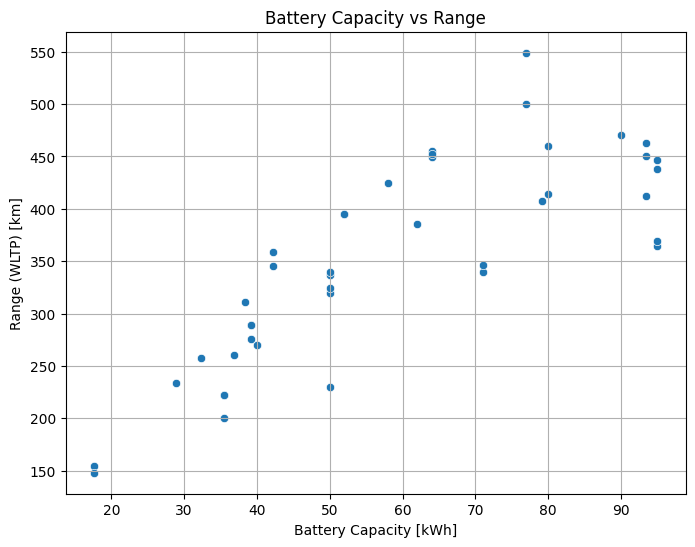

Correlation coefficient: 0.81


In [ ]:
#Taking non null values
valid_corr = df[(df['Battery capacity [kWh]'].notnull()) & (df['Range (WLTP) [km]'].notnull())]

#Creating Plot
plt.figure(figsize=(8,6))
sns.scatterplot(data=valid_corr, x='Battery capacity [kWh]', y='Range (WLTP) [km]')
plt.title('Battery Capacity vs Range')
plt.xlabel('Battery Capacity [kWh]')
plt.ylabel('Range (WLTP) [km]')
plt.grid(True)
plt.show()

#Checking correlation coefficient
correlation = valid_corr['Battery capacity [kWh]'].corr(valid_corr['Range (WLTP) [km]'])
print(f"Correlation coefficient: {correlation:.2f}")

#**INSIGHT OF TASK 3**
* EVs with higher battery capacity tend to offer longer driving range, as shown by a strong correlation coefficient of 0.81.
* This validates battery size as a key predictor of range performance across models.
* Some EVs with 75–95 kWh batteries show less-than-proportional range gains.

# Task 4: Build an EV recommendation class.

In [ ]:
def recommend_evs(df):
    # Asking user for input
    try:
        budget = float(input("Enter your budget (PLN): "))
        min_range = float(input("Enter your desired minimum range (km): "))
        min_battery = float(input("Enter your desired minimum battery capacity (kWh): "))
    except ValueError:
        print("Please enter valid numeric values.")
        return

    # Filtering based on criteria
    filtered = df[
        (df['Minimal price (gross) [PLN]'] <= budget) &
        (df['Range (WLTP) [km]'] >= min_range) &
        (df['Battery capacity [kWh]'] >= min_battery)
    ]

    # Sorting and returning top 3
    top_evs = filtered.sort_values(
        by=['Range (WLTP) [km]', 'Minimal price (gross) [PLN]'],
        ascending=[False, True]
    ).head(3)

    if top_evs.empty:
        print("No EVs match your criteria.")
    else:
        print("\nTop 3 EVs matching your preferences:\n")
        print(top_evs[['Make', 'Model', 'Minimal price (gross) [PLN]', 'Range (WLTP) [km]', 'Battery capacity [kWh]']])
#Calling the function
recommend_evs(df)

Enter your budget (PLN): 300000
Enter your desired minimum range (km): 300
Enter your desired minimum battery capacity (kWh): 70

Top 3 EVs matching your preferences:

          Make       Model  Minimal price (gross) [PLN]  Range (WLTP) [km]  \
48  Volkswagen  ID.3 Pro S                       179990                549   
49  Volkswagen    ID.4 1st                       202390                500   
8          BMW         iX3                       282900                460   

    Battery capacity [kWh]  
48                    77.0  
49                    77.0  
8                     80.0  


This is an interactive function that collects user preferences and filters EVs accordingly. It returns the top 3 matches sorted by range and price, enabling personalized recommendations.

# TASK 5: Inferential Statistics– Hypothesis Testing


T-statistic: 1.79
P-value: 0.1068


<Axes: xlabel='Make', ylabel='Engine power [KM]'>

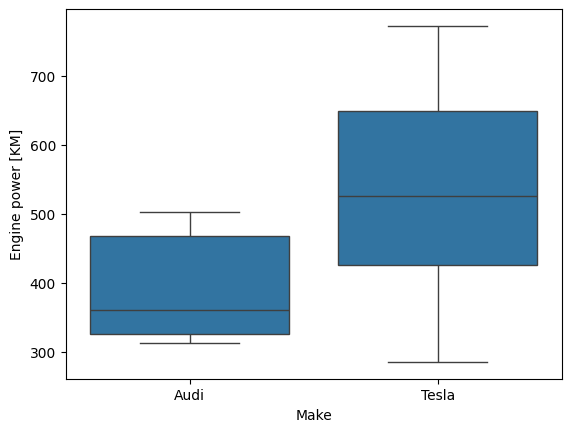

In [ ]:
valid_power = dfd[dfd['Engine power [KM]'].notnull()]
tesla_power = valid_power[valid_power['Make'] == 'Tesla']['Engine power [KM]']
audi_power = valid_power[valid_power['Make'] == 'Audi']['Engine power [KM]']

t_stat, p_value = ttest_ind(tesla_power, audi_power, equal_var=False)
print(f"T-statistic: {t_stat:.2f}")
print(f"P-value: {p_value:.4f}")
sns.boxplot(data=valid_power[valid_power['Make'].isin(['Tesla', 'Audi'])], x='Make', y='Engine power [KM]')


We conducted a two-sample t-test comparing Tesla and Audi engine power. With a p-value of 0.1068, we found no significant difference. This suggests both brands offer similar engine power, and other performance metrics may be more relevant for comparison.
The boxplot shows overlapping distributions of engine power for Tesla and Audi, with similar medians and IQRs. This visual evidence supports our t-test result (p = 0.1068), confirming no significant difference in average engine power between the two brands.

#Interpretation of Task 5
* Since p-value > 0.05, we fail to reject the null hypothesis.

* This means there's no statistically significant difference in average engine power between Tesla and Audi EVs based on the dataset.

#Insights of Task 5
* Despite Tesla’s performance branding, Audi’s EVs offer comparable engine power.

* Engine power alone may not differentiate user experience, factors like torque, acceleration and battery capacity could matter more.

#Recommendations for Task 5
* Customers comparing Tesla and Audi should consider overall performance metrics, not just engine power.

* For product teams: highlight acceleration, range and efficiency in marketing as engine power may not be a clear differentiator.